# Sais: conceito, propriedades e solubilidade
### Funções inorgânicas — sais

**Objetivo:** Definir sal, explicar condução elétrica e ponto de fusão alto e calcular a concentração de sais da água do mar.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

**Sal** é o composto iônico formado por um **cátion** que não seja exclusivamente $\mathrm{H^+}$ e um **ânion** que não seja exclusivamente $\mathrm{OH^-}$. Ele nasce da neutralização de um ácido por uma base:

$$
\boxed{\mathrm{HA + BOH \rightarrow BA + H_2O}}
$$

e, na água, se **dissocia** em íons:

$$
\mathrm{NaCl(s) \xrightarrow{H_2O} Na^+(aq) + Cl^-(aq)}
$$

Isso explica as três propriedades que definem um sal em solução:

| Propriedade | Causa | Consequência prática |
|---|---|---|
| **conduz eletricidade** | íons livres em solução | eletrólito (soro fisiológico conduz) |
| **ponto de fusão alto** | atração eletrostática na rede cristalina | NaCl funde a 801 °C |
| **solubilidade varia muito** | energia da rede × energia de hidratação | NaCl dissolve; AgCl não |

A **solubilidade** é a quantidade máxima de sal que se dissolve em 100 g de água a dada temperatura. Quando o produto das concentrações iônicas passa do limite, o sal precipita:

$$
\mathrm{Ag^+(aq) + Cl^-(aq) \rightleftharpoons AgCl(s)}
\qquad
\boxed{K_{ps} = [\mathrm{Ag^+}][\mathrm{Cl^-}]}
$$

## 2. Exemplo resolvido passo a passo

**Quanto $\mathrm{NaCl}$ há em 1 litro de água do mar?** A salinidade média é $3{,}5\%$ m/m e a densidade da água do mar é $1{,}025\ \mathrm{g/mL}$.

**Passo 1 — massa de 1 L de água do mar.**

$$
m = d\,V = 1{,}025 \cdot 1000 = 1025\ \mathrm{g}
$$

**Passo 2 — massa de sais (3,5% m/m).**

$$
m_{\text{sais}} = 0{,}035 \cdot 1025 = 35{,}9\ \mathrm{g}
$$

**Passo 3 — concentração em mol/L (considerando tudo como NaCl, $M = 58{,}44$).**

$$
c = \frac{35{,}9}{58{,}44} = \boxed{0{,}61\ \mathrm{mol/L}}
$$

**Passo 4 — comparar com o soro fisiológico**, que é NaCl a $0{,}9\%$ m/m ($\approx0{,}154\ \mathrm{mol/L}$):

$$
\frac{0{,}61}{0{,}154} \approx 4
$$

A água do mar é cerca de **4 vezes mais concentrada** em sal que o soro — por isso não se deve beber água do mar.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Salinidade da água do mar x soro fisiológico
import math
from rdkit import Chem
from rdkit.Chem import Descriptors

M_NACL = Descriptors.MolWt(Chem.MolFromSmiles("[Na+].[Cl-]"))
densidade_mar = 1.025     # g/mL
salinidade = 0.035        # 3,5% m/m
volume = 1.000            # L

massa_mar = densidade_mar * volume * 1000
massa_sais = salinidade * massa_mar
concentracao = massa_sais / M_NACL

soro_molaridade = 0.9 / 100 * 1.0 * 1000 / M_NACL     # 0,9% m/m, densidade ~1

print(f"M(NaCl) = {M_NACL:.2f} g/mol")
print(f"massa de 1 L de água do mar: {massa_mar:.0f} g")
print(f"massa de sais:               {massa_sais:.1f} g")
print(f"concentração (como NaCl):    {concentracao:.2f} mol/L")
print(f"soro fisiológico 0,9%:       {soro_molaridade:.3f} mol/L")
print(f"água do mar / soro:          {concentracao / soro_molaridade:.1f}x")
print(f"pressão osmótica (van't Hoff, 25 °C): {2 * concentracao * 0.08206 * 298:.1f} atm")

M(NaCl) = 58.44 g/mol
massa de 1 L de água do mar: 1025 g
massa de sais:               35.9 g
concentração (como NaCl):    0.61 mol/L
soro fisiológico 0,9%:       0.154 mol/L
água do mar / soro:          4.0x
pressão osmótica (van't Hoff, 25 °C): 30.0 atm


## 4. Visualização

### 4.1 Cloreto de sódio em 3D — arraste para girar

O $\mathrm{NaCl}$ é uma rede de íons $\mathrm{Na^+}$ e $\mathrm{Cl^-}$ alternados. A figura mostra o par iônico (a menor unidade de fórmula); no cristal real, cada íon tem 6 vizinhos de carga oposta em um arranjo cúbico.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Na+].[Cl-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Sulfato de cobre(II) em 3D

O $\mathrm{CuSO_4}$ é o sal azul usado em fungicidas e no controle de algas de piscina. O cobre aparece em cor própria no esquema Jmol — gire e localize o átomo central.

In [4]:
molecula_3d("[Cu+2].[O-]S(=O)(=O)[O-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

Repare nas **cargas**: no desenho 2D elas aparecem como sinais sobre os átomos. O número de cargas positivas e negativas tem que se cancelar — é o balanceamento de cargas.

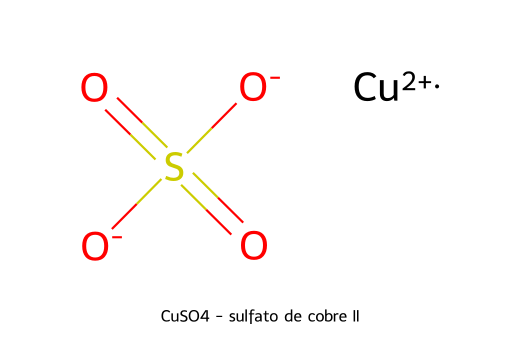

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Na+].[Cl-]", legenda="NaCl - cloreto de sodio")
estrutura_2d("[Cu+2].[O-]S(=O)(=O)[O-]", legenda="CuSO4 - sulfato de cobre II")

### 4.4 Galeria: sais com nomes e usos

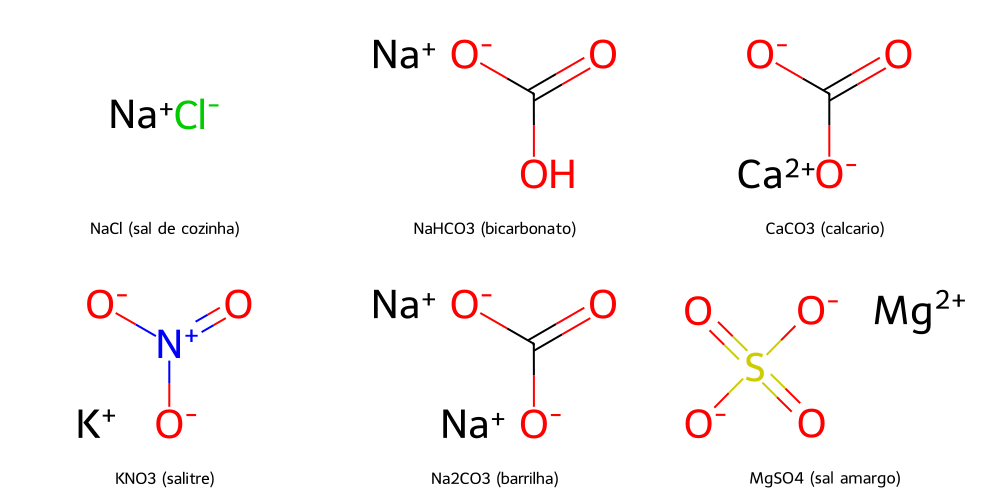

In [6]:
# @title Sais do dia a dia
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

sais = [
    ("NaCl (sal de cozinha)", "[Na+].[Cl-]"),
    ("NaHCO3 (bicarbonato)", "[Na+].OC(=O)[O-]"),
    ("CaCO3 (calcario)", "[Ca+2].[O-]C(=O)[O-]"),
    ("KNO3 (salitre)", "[K+].[O-][N+](=O)[O-]"),
    ("Na2CO3 (barrilha)", "[Na+].[Na+].[O-]C(=O)[O-]"),
    ("MgSO4 (sal amargo)", "[Mg+2].[O-]S(=O)(=O)[O-]"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in sais],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in sais], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 Solubilidade × temperatura

A maioria dos sais aumenta a solubilidade com a temperatura; alguns (como o $\mathrm{Ce_2(SO_4)_3}$) diminuem. É esse comportamento que permite purificar um sal por **recristalização**.

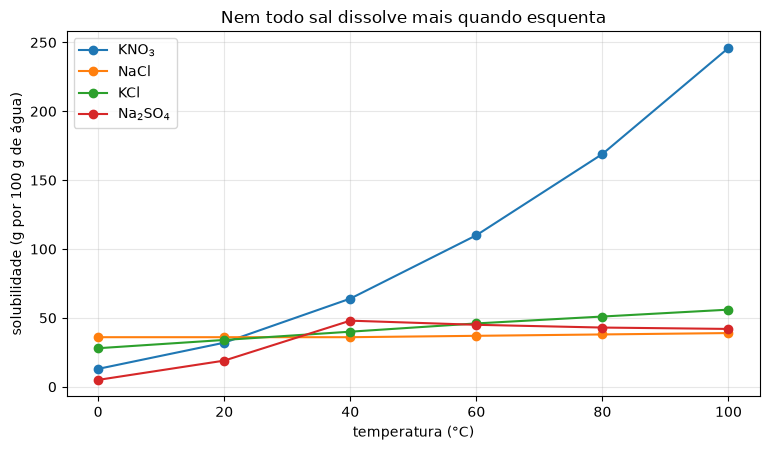

In [7]:
# @title Curvas de solubilidade
import matplotlib.pyplot as plt

temperaturas = [0, 20, 40, 60, 80, 100]
solubilidades = {
    "KNO$_3$": [13, 32, 64, 110, 169, 246],
    "NaCl": [36, 36, 36, 37, 38, 39],
    "KCl": [28, 34, 40, 46, 51, 56],
    "Na$_2$SO$_4$": [5, 19, 48, 45, 43, 42],
}

plt.figure(figsize=(7.8, 4.6))
for nome, valores in solubilidades.items():
    plt.plot(temperaturas, valores, marker="o", label=nome)
plt.xlabel("temperatura (°C)")
plt.ylabel("solubilidade (g por 100 g de água)")
plt.title("Nem todo sal dissolve mais quando esquenta")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 4.6 O produto de solubilidade na prática

In [8]:
# @title Kps e precipitação
from rdkit.Chem import Descriptors

kps = {
    "AgCl": 1.8e-10,
    "AgBr": 5.0e-13,
    "AgI": 8.3e-17,
    "BaSO$_4$": 1.1e-10,
    "CaSO$_4$": 2.4e-5,
    "PbI$_2$": 7.1e-9,
}
formulas = {"AgCl": "[Ag+].[Cl-]", "AgBr": "[Ag+].[Br-]", "AgI": "[Ag+].[I-]",
            "BaSO$_4$": "[Ba+2].[O-]S(=O)(=O)[O-]", "CaSO$_4$": "[Ca+2].[O-]S(=O)(=O)[O-]",
            "PbI$_2$": "[Pb+2].[I-].[I-]"}
estequiometria = {"PbI$_2$": (1, 2)}   # os outros são 1:1

print(f"{'sal':10s} {'Kps':>10s} {'solubilidade (mol/L)':>22s} {'M (g/mol)':>10s}")
for nome, valor in kps.items():
    a, b = estequiometria.get(nome, (1, 1))
    s = (valor / (a ** a * b ** b)) ** (1 / (a + b))
    massa = Descriptors.MolWt(Chem.MolFromSmiles(formulas[nome]))
    print(f"{nome:10s} {valor:10.1e} {s:22.2e} {massa:10.2f}")

sal               Kps   solubilidade (mol/L)  M (g/mol)
AgCl          1.8e-10               1.34e-05     143.32
AgBr          5.0e-13               7.07e-07     187.77
AgI           8.3e-17               9.11e-09     234.77
BaSO$_4$      1.1e-10               1.05e-05     233.39
CaSO$_4$      2.4e-05               4.90e-03     136.14
PbI$_2$       7.1e-09               1.21e-03     461.01


## 5. Como interpretar o resultado

- Sal = cátion + ânion. Só existe sal se as cargas se cancelarem; escrever a fórmula é um exercício de balanceamento de carga.
- A solubilidade define se o sal fica em solução ou precipita. $\mathrm{AgCl}$, $\mathrm{BaSO_4}$ e $\mathrm{PbI_2}$ são "insolúveis" para efeitos práticos, mas todos têm um pouco dissolvido (é o que o $K_{ps}$ mede).
- A água do mar tem $0{,}61\ \mathrm{mol/L}$ de sais: como o NaCl se dissocia em dois íons, a pressão osmótica calculada por van't Hoff dá cerca de 30 atm — é por isso que beber água do mar desidrata.
- No gráfico, o $\mathrm{NaCl}$ é quase uma reta horizontal: por isso se obtém sal marinho por evaporação, não por resfriamento.

## 6. Exercício de fixação

Uma solução contém $\mathrm{Ag^+}$ a $1{,}0\times10^{-4}\ \mathrm{mol/L}$. A partir de que concentração de $\mathrm{Cl^-}$ começa a precipitar $\mathrm{AgCl}$? ($K_{ps} = 1{,}8\times10^{-10}$.)

In [9]:
# @title Exercício
KPS_AGCL = 1.8e-10
AG = 1.0e-4
cl_minimo = KPS_AGCL / AG
print(f"Kps = {KPS_AGCL:.1e}")
print(f"[Cl-] mínima para precipitar = {cl_minimo:.1e} mol/L")
print(f"em massa: {cl_minimo * 35.45 * 1000:.2e} mg/L")
print("(qualquer concentração acima disso forma precipitado branco de AgCl)")

Kps = 1.8e-10
[Cl-] mínima para precipitar = 1.8e-06 mol/L
em massa: 6.38e-02 mg/L
(qualquer concentração acima disso forma precipitado branco de AgCl)


## 7. Resumo

- Sal: composto iônico de cátion (não $\mathrm{H^+}$) com ânion (não $\mathrm{OH^-}$).
- Em água, dissocia em íons → conduz corrente.
- Alta temperatura de fusão por causa da rede cristalina.
- Solubilidade varia com o sal e com a temperatura; limite = $K_{ps}$.
- Salinidade da água do mar $\approx3{,}5\%$ m/m $\approx0{,}61\ \mathrm{mol/L}$.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- SKOOG, D. *Fundamentos de Química Analítica*. Cengage.